<a href="https://colab.research.google.com/github/salnagisa0120/dl-uts-kelompok-17/blob/main/Task_3_Multimodal_Clustering_Material_Type.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 3 — Multimodal Clustering: Material Type

Installasi Library

In [ ]:
!pip -q install numpy pandas matplotlib scikit-learn torch umap-learn


Upload Dataset

In [4]:
import os
import zipfile

# Ganti nama file sesuai dengan nama file zip Anda jika berbeda
zip_file_name = "clustering.zip"

if os.path.exists(zip_file_name):
    print(f"Mengekstrak {zip_file_name}...")
    with zipfile.ZipFile(zip_file_name, 'r') as zip_ref:
        zip_ref.extractall("/content")
    print("Ekstraksi selesai!")
else:
    # Mencari file zip apa saja yang ada di folder jika nama di atas tidak cocok
    all_zips = [f for f in os.listdir('.') if f.endswith('.zip')]
    if all_zips:
        chosen_zip = all_zips[0]
        print(f"Menemukan berkas zip: {chosen_zip}. Mengekstrak...")
        with zipfile.ZipFile(chosen_zip, 'r') as zip_ref:
            zip_ref.extractall("/content")
        print("Ekstraksi selesai!")
    else:
        print("Gagal: Tidak ditemukan berkas .zip di folder /content. Silakan unggah berkas .zip Anda terlebih dahulu.")

# Verifikasi file setelah ekstraksi
required_files = {"clustering.npz", "clustering_meta.csv"}
missing = {f for f in required_files if not os.path.exists(f)}
if not missing:
    print("Semua dataset yang diperlukan ditemukan dan siap digunakan!")
else:
    print(f"Peringatan: Berkas berikut masih belum ditemukan: {missing}")

Menemukan berkas zip: data_uts_dl.zip. Mengekstrak...
Ekstraksi selesai!
Semua dataset yang diperlukan ditemukan dan siap digunakan!


Konfigurasi

In [8]:
# Konfigurasi
EPOCHS = 30
DEC_EPOCHS = 80
BATCH_SIZE = 256
LATENT_DIM = 64
K_MIN = 2
K_MAX = 12
USE_UMAP = True  # False menggunakan PCA yang lebih ringan

import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Perangkat:", DEVICE)


Perangkat: cuda


Pipeline untuk multimodal

In [9]:
# Simpan implementasi pipeline sebagai file Python agar mudah dijalankan ulang.
pipeline_code = r'''"""
Task 3 - Multimodal Clustering: Material Types
Dataset:
  clustering.npz: gambar (N,64,64), spektrum (N,128)
  clustering_meta.csv: indeks, id_sampel, mikroskop

Unsupervised pipeline:
  augmentation -> modality-specific denoising autoencoders -> embedding fusion
  -> KMeans / GMM / DEC -> cluster-count diagnostics -> UMAP/PCA -> optional ARI

Example:
  python multimodal_clustering.py --data clustering.npz --meta clustering_meta.csv
  python multimodal_clustering.py --epochs 30 --batch-size 256 --k-min 2 --k-max 12
"""

import argparse
import json
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, normalize
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore", category=UserWarning)


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def load_dataset(npz_path, meta_path):
    data = np.load(npz_path, allow_pickle=False)
    required = {"gambar", "spektrum"}
    if not required.issubset(data.files):
        raise ValueError(f"NPZ harus memiliki keys {required}; ditemukan {data.files}")

    images = data["gambar"]
    spectra = data["spektrum"].astype(np.float32)
    meta = pd.read_csv(meta_path)

    if len(images) != len(spectra) or len(images) != len(meta):
        raise ValueError("Jumlah baris gambar, spektrum, dan metadata tidak sama.")
    if images.ndim == 3:
        images = images[:, None, :, :]
    elif images.ndim == 4 and images.shape[-1] in (1, 3):
        images = np.transpose(images, (0, 3, 1, 2))
    elif images.ndim != 4:
        raise ValueError(f"Format gambar tidak didukung: {images.shape}")

    images = images.astype(np.float32)
    if images.max() > 1.0:
        images /= 255.0

    # Robust per-sample spectrum scaling. Preserve spectral shape while limiting outliers.
    med = np.median(spectra, axis=1, keepdims=True)
    q1 = np.percentile(spectra, 25, axis=1, keepdims=True)
    q3 = np.percentile(spectra, 75, axis=1, keepdims=True)
    spectra = (spectra - med) / np.maximum(q3 - q1, 1e-4)
    spectra = np.clip(spectra, -8, 8)

    return images, spectra.astype(np.float32), meta


class MultiModalDataset(Dataset):
    def __init__(self, images, spectra):
        self.images = torch.tensor(images, dtype=torch.float32)
        self.spectra = torch.tensor(spectra, dtype=torch.float32)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.images[idx], self.spectra[idx]


def augment_image(x):
    """Small rotations, flips, scale/translation, brightness and Gaussian noise."""
    b = x.shape[0]
    if random.random() < 0.5:
        x = torch.flip(x, dims=[3])
    if random.random() < 0.5:
        x = torch.flip(x, dims=[2])
    # k=0..3 rotations preserve square image dimensions
    k = random.randint(0, 3)
    x = torch.rot90(x, k, dims=[2, 3])
    scale = 0.90 + 0.20 * torch.rand(b, 1, 1, 1, device=x.device)
    brightness = 0.85 + 0.30 * torch.rand(b, 1, 1, 1, device=x.device)
    x = x * scale * brightness
    x = x + 0.025 * torch.randn_like(x)
    return x.clamp(0, 1)


def augment_spectrum(x):
    """Spectral shift, smooth baseline drift, noise and sparse spike artifacts."""
    b, length = x.shape
    shifted = torch.zeros_like(x)
    shifts = torch.randint(-3, 4, (b,), device=x.device)
    for i, s in enumerate(shifts.tolist()):
        shifted[i] = torch.roll(x[i], shifts=s, dims=0)

    t = torch.linspace(-1, 1, length, device=x.device).unsqueeze(0)
    slope = torch.randn(b, 1, device=x.device) * 0.12
    offset = torch.randn(b, 1, device=x.device) * 0.08
    curvature = torch.randn(b, 1, device=x.device) * 0.04
    baseline = offset + slope * t + curvature * (t ** 2)

    noisy = shifted + baseline + 0.04 * torch.randn_like(shifted)
    spike_mask = (torch.rand_like(noisy) < 0.008).float()
    spikes = torch.randn_like(noisy) * 1.5 * spike_mask
    return noisy + spikes


class ImageEncoder(nn.Module):
    def __init__(self, in_channels=1, latent=64):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, 32, 3, stride=2, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 128, 3, stride=2, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 256), nn.ReLU(),
            nn.Linear(256, latent)
        )

    def forward(self, x):
        return self.conv(x)


class ImageAutoencoder(nn.Module):
    def __init__(self, in_channels=1, latent=64):
        super().__init__()
        self.encoder = ImageEncoder(in_channels, latent)
        self.decoder_fc = nn.Sequential(nn.Linear(latent, 128 * 8 * 8), nn.ReLU())
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, in_channels, 4, stride=2, padding=1), nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        y = self.decoder_fc(z).view(-1, 128, 8, 8)
        return self.decoder(y), z


class SpectrumAutoencoder(nn.Module):
    def __init__(self, input_dim=128, latent=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 256), nn.BatchNorm1d(256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, latent)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent, 128), nn.ReLU(),
            nn.Linear(128, 256), nn.ReLU(),
            nn.Linear(256, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z


def train_autoencoders(images, spectra, args, device, out_dir):
    dataset = MultiModalDataset(images, spectra)
    loader = DataLoader(dataset, batch_size=args.batch_size, shuffle=True,
                        num_workers=args.workers, pin_memory=(device.type == "cuda"),
                        drop_last=False)

    img_model = ImageAutoencoder(images.shape[1], args.latent_dim).to(device)
    spec_model = SpectrumAutoencoder(spectra.shape[1], args.latent_dim).to(device)
    opt = torch.optim.AdamW(
        list(img_model.parameters()) + list(spec_model.parameters()),
        lr=args.lr, weight_decay=1e-5
    )
    mse = nn.MSELoss()

    for epoch in range(args.epochs):
        img_model.train()
        spec_model.train()
        total_img, total_spec, count = 0.0, 0.0, 0
        for img, spec in loader:
            img, spec = img.to(device), spec.to(device)
            img_aug = augment_image(img)
            spec_aug = augment_spectrum(spec)

            img_recon, _ = img_model(img_aug)
            spec_recon, _ = spec_model(spec_aug)
            loss_img = mse(img_recon, img)
            loss_spec = mse(spec_recon, spec)
            loss = loss_img + loss_spec

            opt.zero_grad()
            loss.backward()
            opt.step()

            n = len(img)
            total_img += loss_img.item() * n
            total_spec += loss_spec.item() * n
            count += n

        print(f"Epoch {epoch+1:03d}/{args.epochs} | "
              f"image_loss={total_img/count:.5f} | spectrum_loss={total_spec/count:.5f}")

    torch.save(img_model.state_dict(), out_dir / "image_autoencoder.pt")
    torch.save(spec_model.state_dict(), out_dir / "spectrum_autoencoder.pt")
    return img_model, spec_model


@torch.no_grad()
def extract_embeddings(img_model, spec_model, images, spectra, args, device):
    img_model.eval()
    spec_model.eval()
    loader = DataLoader(MultiModalDataset(images, spectra), batch_size=args.batch_size,
                        shuffle=False, num_workers=args.workers)
    zi, zs = [], []
    for img, spec in loader:
        img, spec = img.to(device), spec.to(device)
        zi.append(img_model.encoder(img).cpu().numpy())
        zs.append(spec_model.encoder(spec).cpu().numpy())
    zi, zs = np.vstack(zi), np.vstack(zs)
    # Standardize each modality independently so one modality does not dominate by scale.
    zi = StandardScaler().fit_transform(zi)
    zs = StandardScaler().fit_transform(zs)
    fused = normalize(np.concatenate([zi, zs], axis=1))
    return zi.astype(np.float32), zs.astype(np.float32), fused.astype(np.float32)


def dec_cluster(embedding, n_clusters, device, epochs=80, batch_size=512):
    """Compact DEC implementation initialized with KMeans."""
    x = torch.tensor(embedding, dtype=torch.float32, device=device)
    n, dim = x.shape
    km = KMeans(n_clusters=n_clusters, n_init=10, random_state=42).fit(embedding)
    centers = torch.tensor(km.cluster_centers_, dtype=torch.float32, device=device)

    class DECNet(nn.Module):
        def __init__(self, d):
            super().__init__()
            self.encoder = nn.Sequential(nn.Linear(d, 128), nn.ReLU(),
                                         nn.Linear(128, 64), nn.ReLU(),
                                         nn.Linear(64, 32))
            self.cluster_centers = nn.Parameter(torch.randn(n_clusters, 32) * 0.02)

        def forward(self, inp):
            z = self.encoder(inp)
            dist = torch.sum((z[:, None, :] - self.cluster_centers[None, :, :]) ** 2, dim=2)
            q = 1.0 / (1.0 + dist)
            q = q / q.sum(dim=1, keepdim=True)
            return z, q

    model = DECNet(dim).to(device)
    with torch.no_grad():
        model.cluster_centers.copy_(centers.new_zeros((n_clusters, 32)))
        # Initialize DEC latent centers from encoded points.
        z0 = model.encoder(x)
        model.cluster_centers.copy_(torch.tensor(
            KMeans(n_clusters=n_clusters, n_init=10, random_state=42).fit(
                z0.detach().cpu().numpy()).cluster_centers_,
            dtype=torch.float32, device=device
        ))

    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    previous = None
    for epoch in range(epochs):
        with torch.no_grad():
            _, q_all = model(x)
            weight = (q_all ** 2) / q_all.sum(dim=0, keepdim=True)
            p_all = (weight.t() / weight.sum(dim=1)).t()
        perm = torch.randperm(n, device=device)
        for start in range(0, n, batch_size):
            ids = perm[start:start+batch_size]
            _, q = model(x[ids])
            p = p_all[ids]
            loss = torch.sum(p * torch.log((p + 1e-8) / (q + 1e-8))) / len(ids)
            opt.zero_grad()
            loss.backward()
            opt.step()
        if epoch % 10 == 0 or epoch == epochs - 1:
            with torch.no_grad():
                labels = model(x)[1].argmax(1).cpu().numpy()
            if previous is not None:
                change = np.mean(labels != previous)
                if change < 0.001:
                    break
            previous = labels
    with torch.no_grad():
        labels = model(x)[1].argmax(1).cpu().numpy()
    return labels


def evaluate_k(embedding, labels, sample_size=5000):
    # Silhouette on a deterministic subset keeps computation practical at N=36k.
    if len(np.unique(labels)) < 2:
        return np.nan, np.nan, np.nan
    rng = np.random.RandomState(42)
    ids = rng.choice(len(embedding), min(sample_size, len(embedding)), replace=False)
    sub_x, sub_y = embedding[ids], labels[ids]
    if len(np.unique(sub_y)) < 2:
        sil = np.nan
    else:
        sil = silhouette_score(sub_x, sub_y)
    return sil, davies_bouldin_score(embedding, labels), calinski_harabasz_score(embedding, labels)


def choose_k(embedding, k_min, k_max, out_dir):
    rows = []
    for k in range(k_min, k_max + 1):
        labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(embedding)
        sil, db, ch = evaluate_k(embedding, labels)
        rows.append({"k": k, "silhouette": sil, "davies_bouldin": db,
                     "calinski_harabasz": ch})
        print(f"k={k:2d} | silhouette={sil:.4f} | DB={db:.4f} | CH={ch:.1f}")
    scores = pd.DataFrame(rows)
    scores.to_csv(out_dir / "cluster_count_metrics.csv", index=False)

    # Two explicit criteria: maximize silhouette and minimize Davies-Bouldin.
    best_sil = int(scores.loc[scores.silhouette.idxmax(), "k"])
    best_db = int(scores.loc[scores.davies_bouldin.idxmin(), "k"])
    # Consensus rank: equal weight for silhouette rank and DB rank.
    scores["sil_rank"] = scores["silhouette"].rank(ascending=False)
    scores["db_rank"] = scores["davies_bouldin"].rank(ascending=True)
    scores["rank_sum"] = scores["sil_rank"] + scores["db_rank"]
    best_consensus = int(scores.loc[scores.rank_sum.idxmin(), "k"])
    scores.to_csv(out_dir / "cluster_count_metrics.csv", index=False)
    print(f"\nKriteria 1 (silhouette maksimum): k={best_sil}")
    print(f"Kriteria 2 (Davies-Bouldin minimum): k={best_db}")
    print(f"Konsensus peringkat dua kriteria: k={best_consensus}")
    return best_consensus, scores


def plot_cluster_metrics(scores, out_dir):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, col, title in zip(
        axes, ["silhouette", "davies_bouldin", "calinski_harabasz"],
        ["Silhouette (lebih tinggi)", "Davies-Bouldin (lebih rendah)",
         "Calinski-Harabasz (lebih tinggi)"]
    ):
        ax.plot(scores["k"], scores[col], marker="o")
        ax.set_xlabel("Jumlah cluster (k)")
        ax.set_ylabel(col)
        ax.set_title(title)
        ax.grid(alpha=.25)
    fig.tight_layout()
    fig.savefig(out_dir / "cluster_count_diagnostics.png", dpi=180)
    plt.close(fig)


def reduce_dimensions(x, method="umap"):
    if method == "umap":
        try:
            import umap
            return umap.UMAP(n_neighbors=30, min_dist=0.1, n_components=2,
                             metric="cosine", random_state=42).fit_transform(x), "UMAP"
        except ImportError:
            print("Package umap-learn tidak tersedia; memakai PCA.")
    return PCA(n_components=2, random_state=42).fit_transform(x), "PCA"


def plot_embedding(x, labels, title, path, method="umap", max_points=12000):
    coords, method_name = reduce_dimensions(x, method)
    rng = np.random.RandomState(42)
    ids = rng.choice(len(x), min(max_points, len(x)), replace=False)
    fig, ax = plt.subplots(figsize=(9, 7))
    scatter = ax.scatter(coords[ids, 0], coords[ids, 1], c=labels[ids],
                         s=5, alpha=.65, cmap="tab20")
    ax.set_title(f"{title} - {method_name}")
    ax.set_xlabel(f"{method_name} 1")
    ax.set_ylabel(f"{method_name} 2")
    fig.colorbar(scatter, ax=ax, label="Cluster")
    fig.tight_layout()
    fig.savefig(path, dpi=180)
    plt.close(fig)


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--data", default="/content/clustering.npz")
    parser.add_argument("--meta", default="/content/clustering_meta.csv")
    parser.add_argument("--output", default="/content/hasil_clustering")
    parser.add_argument("--epochs", type=int, default=30)
    parser.add_argument("--batch-size", type=int, default=256)
    parser.add_argument("--latent-dim", type=int, default=64)
    parser.add_argument("--lr", type=float, default=1e-3)
    parser.add_argument("--workers", type=int, default=0)
    parser.add_argument("--k-min", type=int, default=2)
    parser.add_argument("--k-max", type=int, default=12)
    parser.add_argument("--dec-epochs", type=int, default=80)
    parser.add_argument("--umap", action="store_true",
                        help="Gunakan UMAP; tanpa flag memakai PCA yang lebih ringan.")
    parser.add_argument("--seed", type=int, default=42)
    args = parser.parse_args(args=[])

    seed_everything(args.seed)
    out_dir = Path(args.output)
    out_dir.mkdir(parents=True, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Device:", device)

    images, spectra, meta = load_dataset(args.data, args.meta)
    print(f"Data: {len(images)} sampel | gambar={images.shape} | spektrum={spectra.shape}")
    print("Metadata:", list(meta.columns))
    print("Distribusi mikroskop (informasi metadata, bukan label material):")
    if "mikroskop" in meta:
        print(meta["mikroskop"].value_counts(dropna=False))

    img_model, spec_model = train_autoencoders(images, spectra, args, device, out_dir)
    zi, zs, fused = extract_embeddings(img_model, spec_model, images, spectra, args, device)

    np.savez_compressed(out_dir / "embeddings.npz",
                        image_embedding=zi, spectrum_embedding=zs, fused_embedding=fused)

    # Select k using the fused representation and two independent validity criteria.
    best_k, metrics = choose_k(fused, args.k_min, args.k_max, out_dir)
    plot_cluster_metrics(metrics, out_dir)

    results = {}
    representations = {
        "image_only": zi,
        "spectrum_only": zs,
        "multimodal_fusion": fused
    }

    for rep_name, emb in representations.items():
        km = KMeans(n_clusters=best_k, n_init=20, random_state=args.seed).fit_predict(emb)
        gm = GaussianMixture(n_components=best_k, covariance_type="diag",
                             random_state=args.seed, reg_covar=1e-5).fit(emb).predict(emb)
        results[f"{rep_name}_kmeans"] = km
        results[f"{rep_name}_gmm"] = gm

        # Evaluate the two conventional algorithms for fair comparison.
        for method, labels in [("kmeans", km), ("gmm", gm)]:
            sil, db, ch = evaluate_k(emb, labels)
            print(f"{rep_name}/{method}: silhouette={sil:.4f}, DB={db:.4f}, CH={ch:.1f}")

    dec_labels = dec_cluster(fused, best_k, device, args.dec_epochs, args.batch_size)
    results["multimodal_fusion_dec"] = dec_labels
    sil, db, ch = evaluate_k(fused, dec_labels)
    print(f"multimodal_fusion/DEC: silhouette={sil:.4f}, DB={db:.4f}, CH={ch:.1f}")

    # Persist labels and metadata for downstream interpretation.
    result_df = meta.copy()
    for name, labels in results.items():
        result_df[name] = labels
    result_df.to_csv(out_dir / "cluster_assignments.csv", index=False)

    # Visual comparison: image-only, spectrum-only, and fused.
    plot_method = "umap" if args.umap else "pca"
    plot_embedding(fused, results["multimodal_fusion_kmeans"],
                   "Multimodal fusion + KMeans",
                   out_dir / "embedding_fusion_kmeans.png", plot_method)
    plot_embedding(zi, results["image_only_kmeans"],
                   "Image-only + KMeans",
                   out_dir / "embedding_image_only.png", plot_method)
    plot_embedding(zs, results["spectrum_only_kmeans"],
                   "Spectrum-only + KMeans",
                   out_dir / "embedding_spectrum_only.png", plot_method)
    plot_embedding(fused, dec_labels, "Multimodal fusion + DEC",
                   out_dir / "embedding_fusion_dec.png", plot_method)

    # ARI is valid only if a real material ground-truth column exists.
    candidate_labels = ["material_type", "jenis_material", "label_material",
                        "true_label", "ground_truth"]
    gt_col = next((c for c in candidate_labels if c in meta.columns), None)
    ari_report = {"ground_truth_column": gt_col, "ARI": None}
    if gt_col is not None:
        valid = meta[gt_col].notna().to_numpy()
        ari_report["ARI"] = {
            name: float(adjusted_rand_score(meta.loc[valid, gt_col], labels[valid]))
            for name, labels in results.items()
        }
        print("ARI:", ari_report["ARI"])
    else:
        print("\nARI tidak dihitung: metadata tidak menyediakan label material sebenarnya.")
        print("Kolom 'mikroskop' tidak digunakan sebagai ground-truth karena hanya menunjukkan jenis mikroskop.")
    with open(out_dir / "evaluation_summary.json", "w", encoding="utf-8") as f:
        json.dump({
            "n_samples": len(images), "selected_k": best_k,
            "k_criteria": {
                "silhouette_best_k": int(metrics.loc[metrics.silhouette.idxmax(), "k"]),
                "davies_bouldin_best_k": int(metrics.loc[metrics.davies_bouldin.idxmin(), "k"])
            },
            "ari": ari_report
        }, f, indent=2, ensure_ascii=False)

    print(f"\nSelesai. Seluruh hasil tersimpan di: {out_dir.resolve()}")


if __name__ == "__main__":
    main()
'''
with open("/content/multimodal_clustering.py", "w", encoding="utf-8") as f:
    f.write(pipeline_code)

# Jalankan pipeline dengan konfigurasi notebook.
import sys
sys.argv = [
    "multimodal_clustering.py",
    "--data", "/content/clustering.npz",
    "--meta", "/content/clustering_meta.csv",
    "--output", "/content/hasil_clustering",
    "--epochs", str(EPOCHS),
    "--dec-epochs", str(DEC_EPOCHS),
    "--batch-size", str(BATCH_SIZE),
    "--latent-dim", str(LATENT_DIM),
    "--k-min", str(K_MIN),
    "--k-max", str(K_MAX),
]
if USE_UMAP:
    sys.argv.append("--umap")

%run /content/multimodal_clustering.py


Device: cuda
Data: 36000 sampel | gambar=(36000, 1, 64, 64) | spektrum=(36000, 128)
Metadata: ['indeks', 'id_sampel', 'mikroskop']
Distribusi mikroskop (informasi metadata, bukan label material):
mikroskop
M1    21636
M2    14364
Name: count, dtype: int64
Epoch 001/30 | image_loss=0.00821 | spectrum_loss=0.55496
Epoch 002/30 | image_loss=0.00786 | spectrum_loss=0.33257
Epoch 003/30 | image_loss=0.00782 | spectrum_loss=0.29480
Epoch 004/30 | image_loss=0.00775 | spectrum_loss=0.26956
Epoch 005/30 | image_loss=0.00764 | spectrum_loss=0.25662
Epoch 006/30 | image_loss=0.00740 | spectrum_loss=0.24795
Epoch 007/30 | image_loss=0.00726 | spectrum_loss=0.24378
Epoch 008/30 | image_loss=0.00722 | spectrum_loss=0.23914
Epoch 009/30 | image_loss=0.00718 | spectrum_loss=0.23626
Epoch 010/30 | image_loss=0.00718 | spectrum_loss=0.23225
Epoch 011/30 | image_loss=0.00711 | spectrum_loss=0.23084
Epoch 012/30 | image_loss=0.00712 | spectrum_loss=0.22768
Epoch 013/30 | image_loss=0.00705 | spectrum_los

<Figure size 640x480 with 0 Axes>

Laporan Program

,k,silhouette,davies_bouldin,calinski_harabasz,sil_rank,db_rank,rank_sum
0,2,0.269197,1.514690,15318.5430,1.0,1.0,2.0
1,3,0.203622,1.917211,10047.7290,2.0,3.0,5.0
2,4,0.160701,2.101674,8235.6570,5.0,11.0,16.0
3,5,0.152476,2.098771,6989.0317,10.0,10.0,20.0
4,6,0.151309,2.070257,6218.7800,11.0,9.0,20.0
5,7,0.158879,2.023042,5792.5530,6.0,7.0,13.0
6,8,0.165541,1.962154,5461.9243,3.0,5.0,8.0
7,9,0.161204,2.046593,5095.7670,4.0,8.0,12.0
8,10,0.158756,1.975465,4776.0537,7.0,6.0,13.0
9,11,0.156085,1.904269,4518.4850,8.0,2.0,10.0


{
  "n_samples": 36000,
  "selected_k": 2,
  "k_criteria": {
    "silhouette_best_k": 2,
    "davies_bouldin_best_k": 2
  },
  "ari": {
    "ground_truth_column": null,
    "ARI": null
  }
}
cluster_count_diagnostics.png


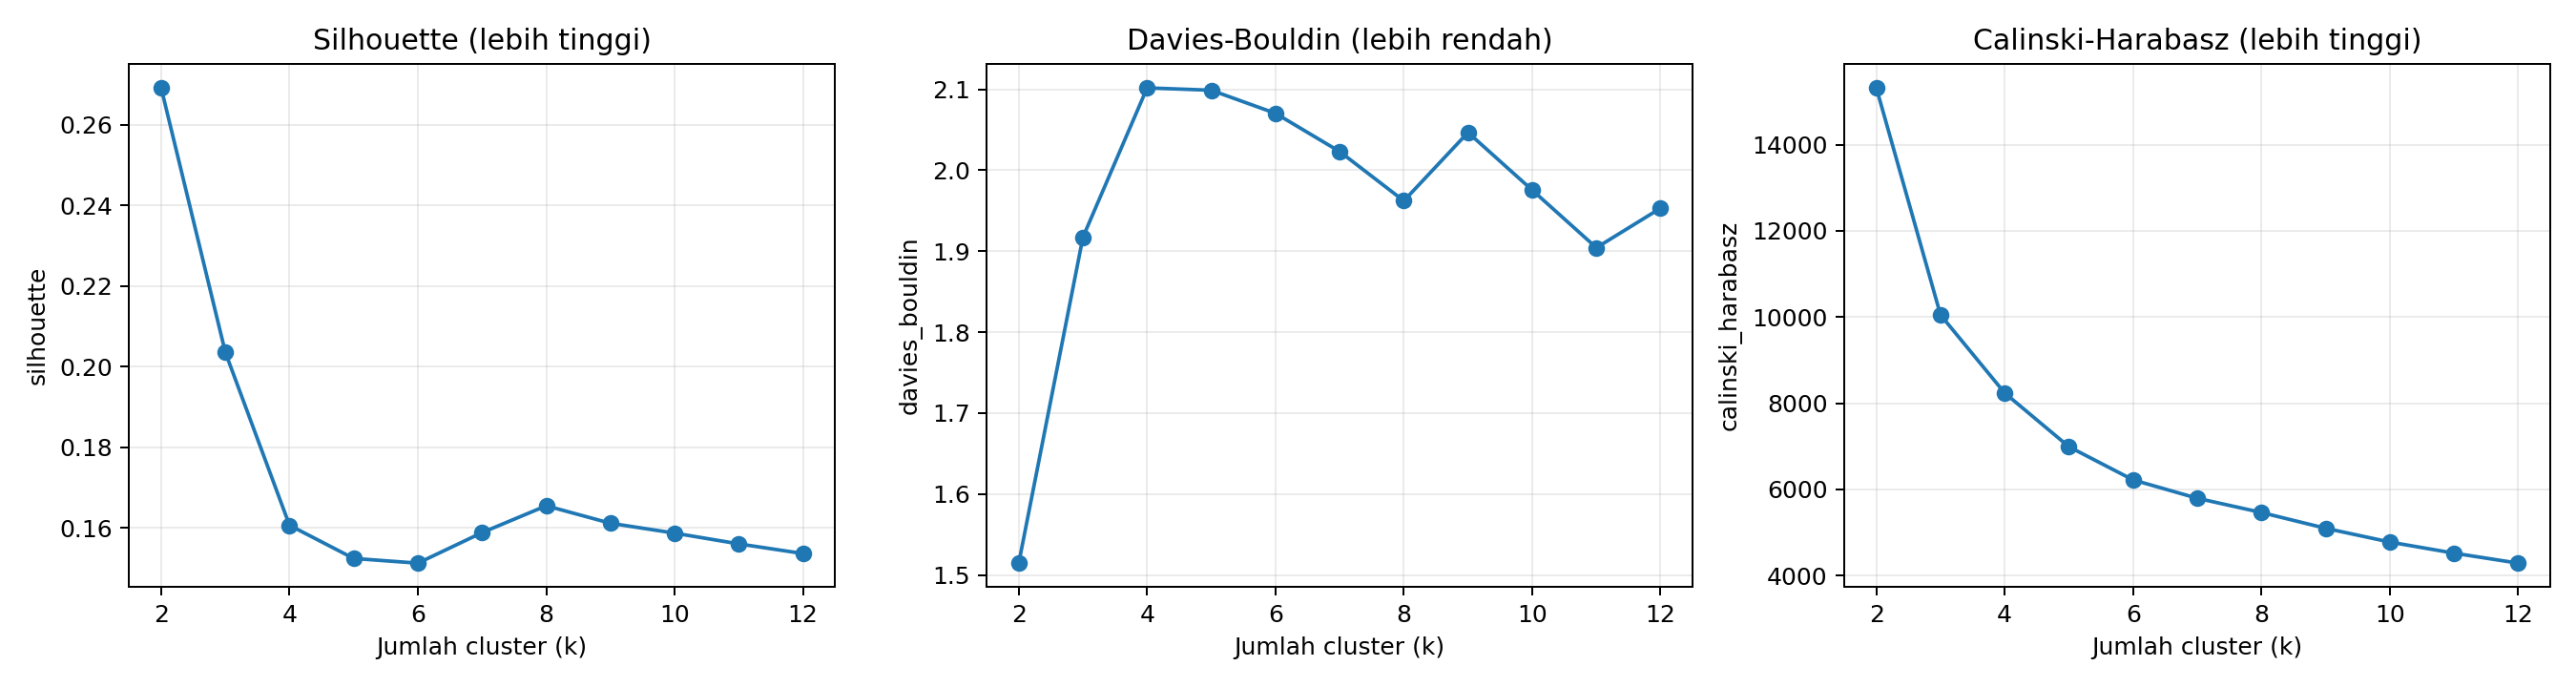

embedding_fusion_kmeans.png


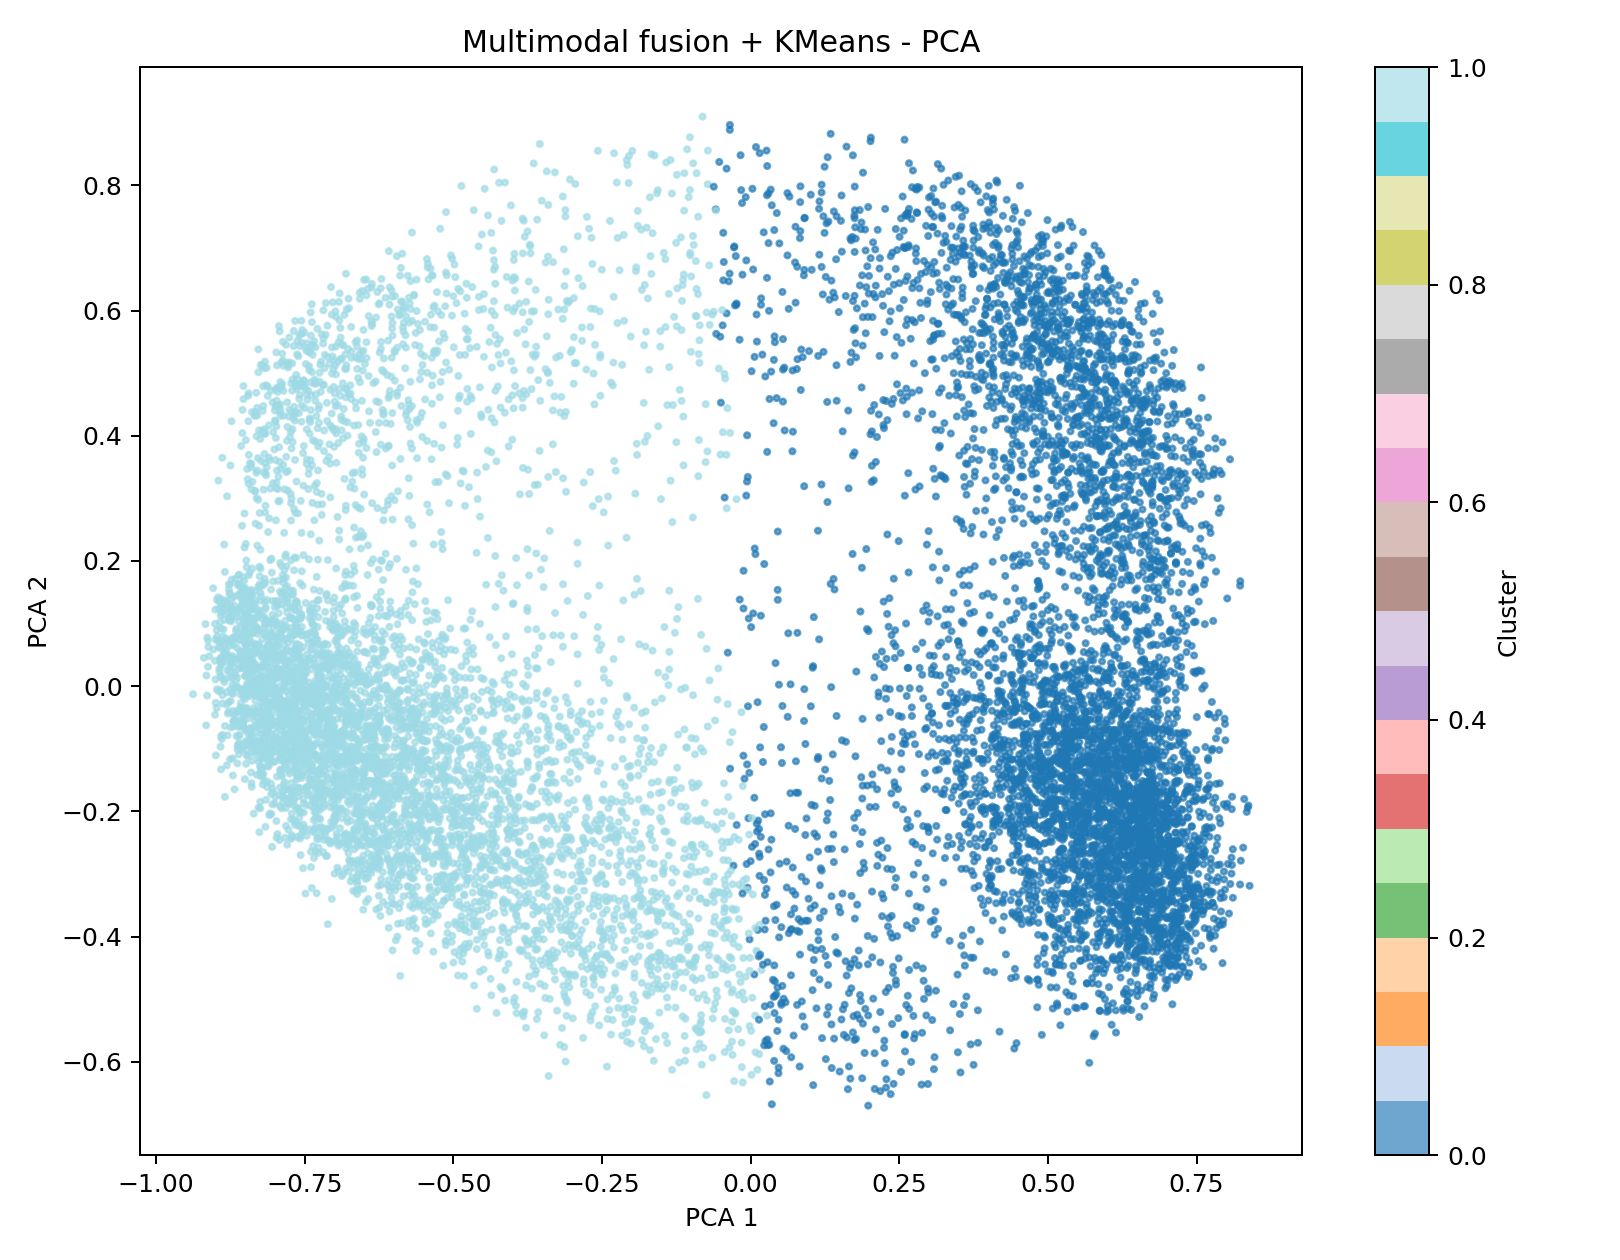

embedding_image_only.png


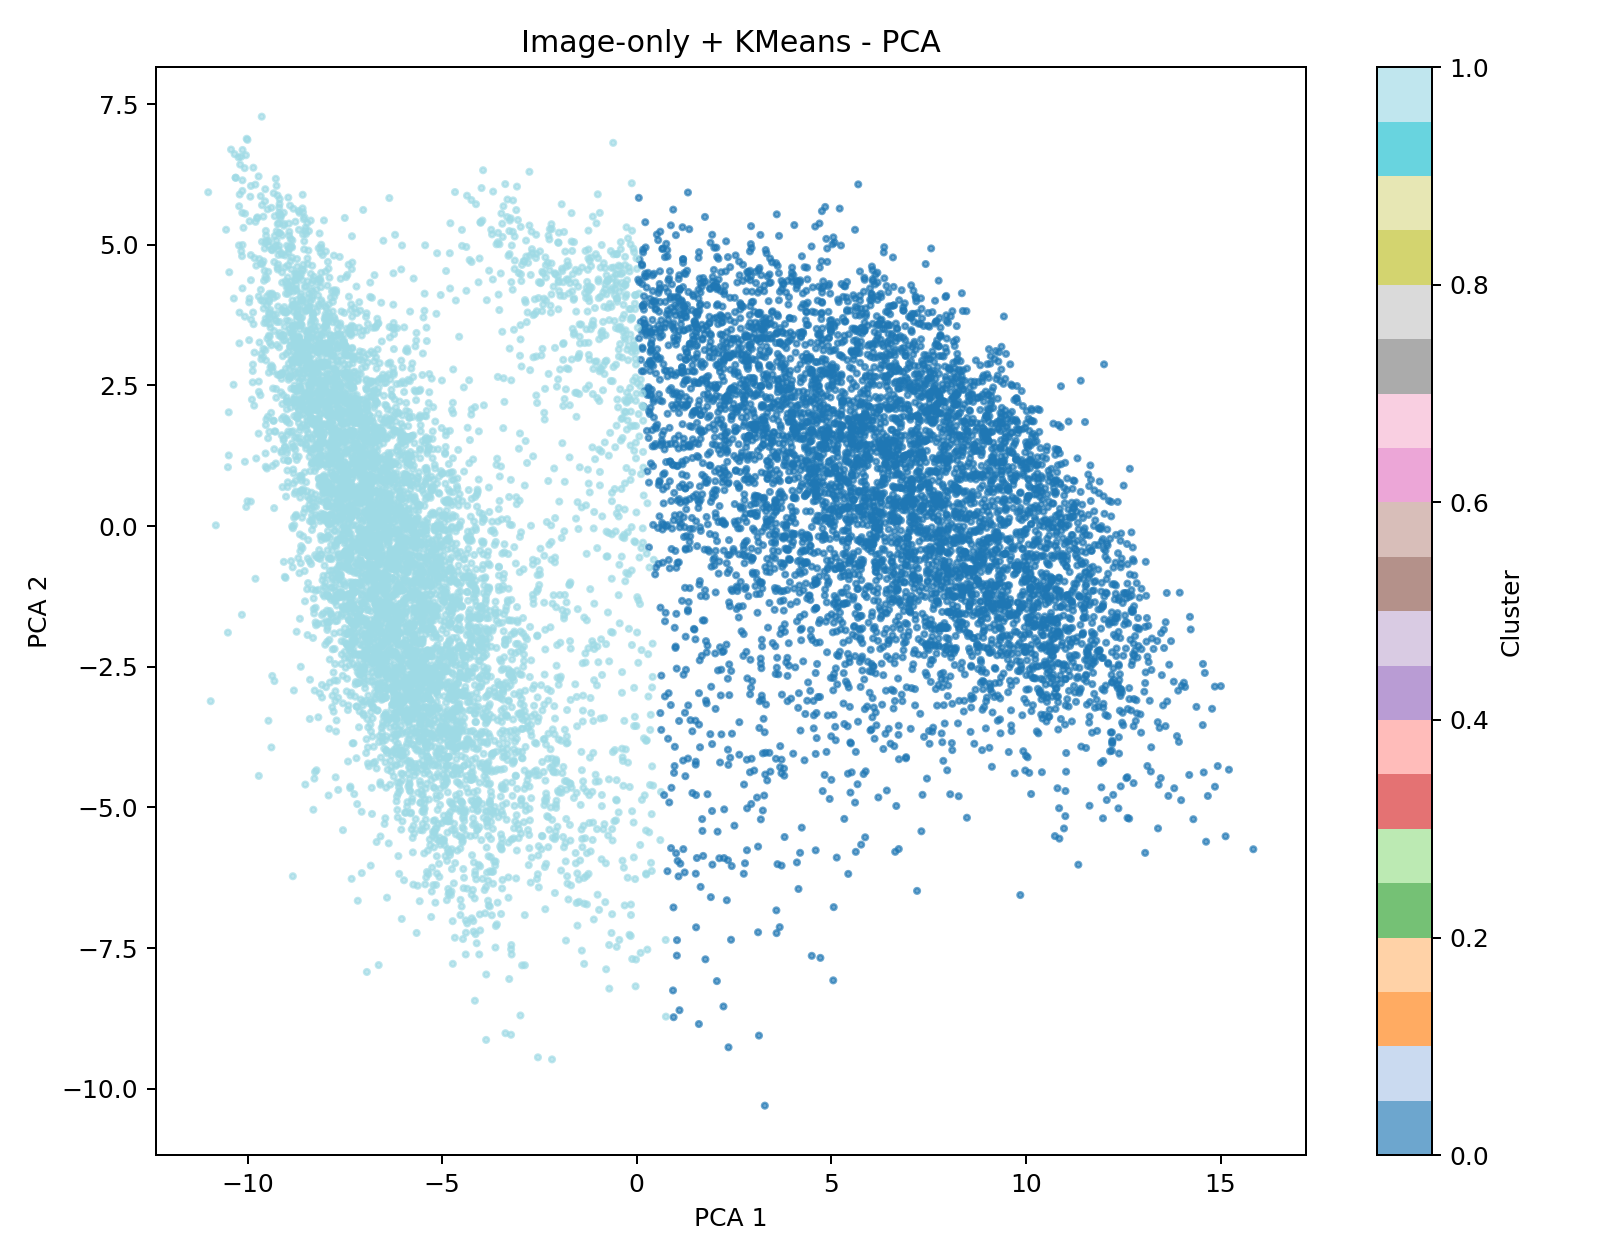

embedding_spectrum_only.png


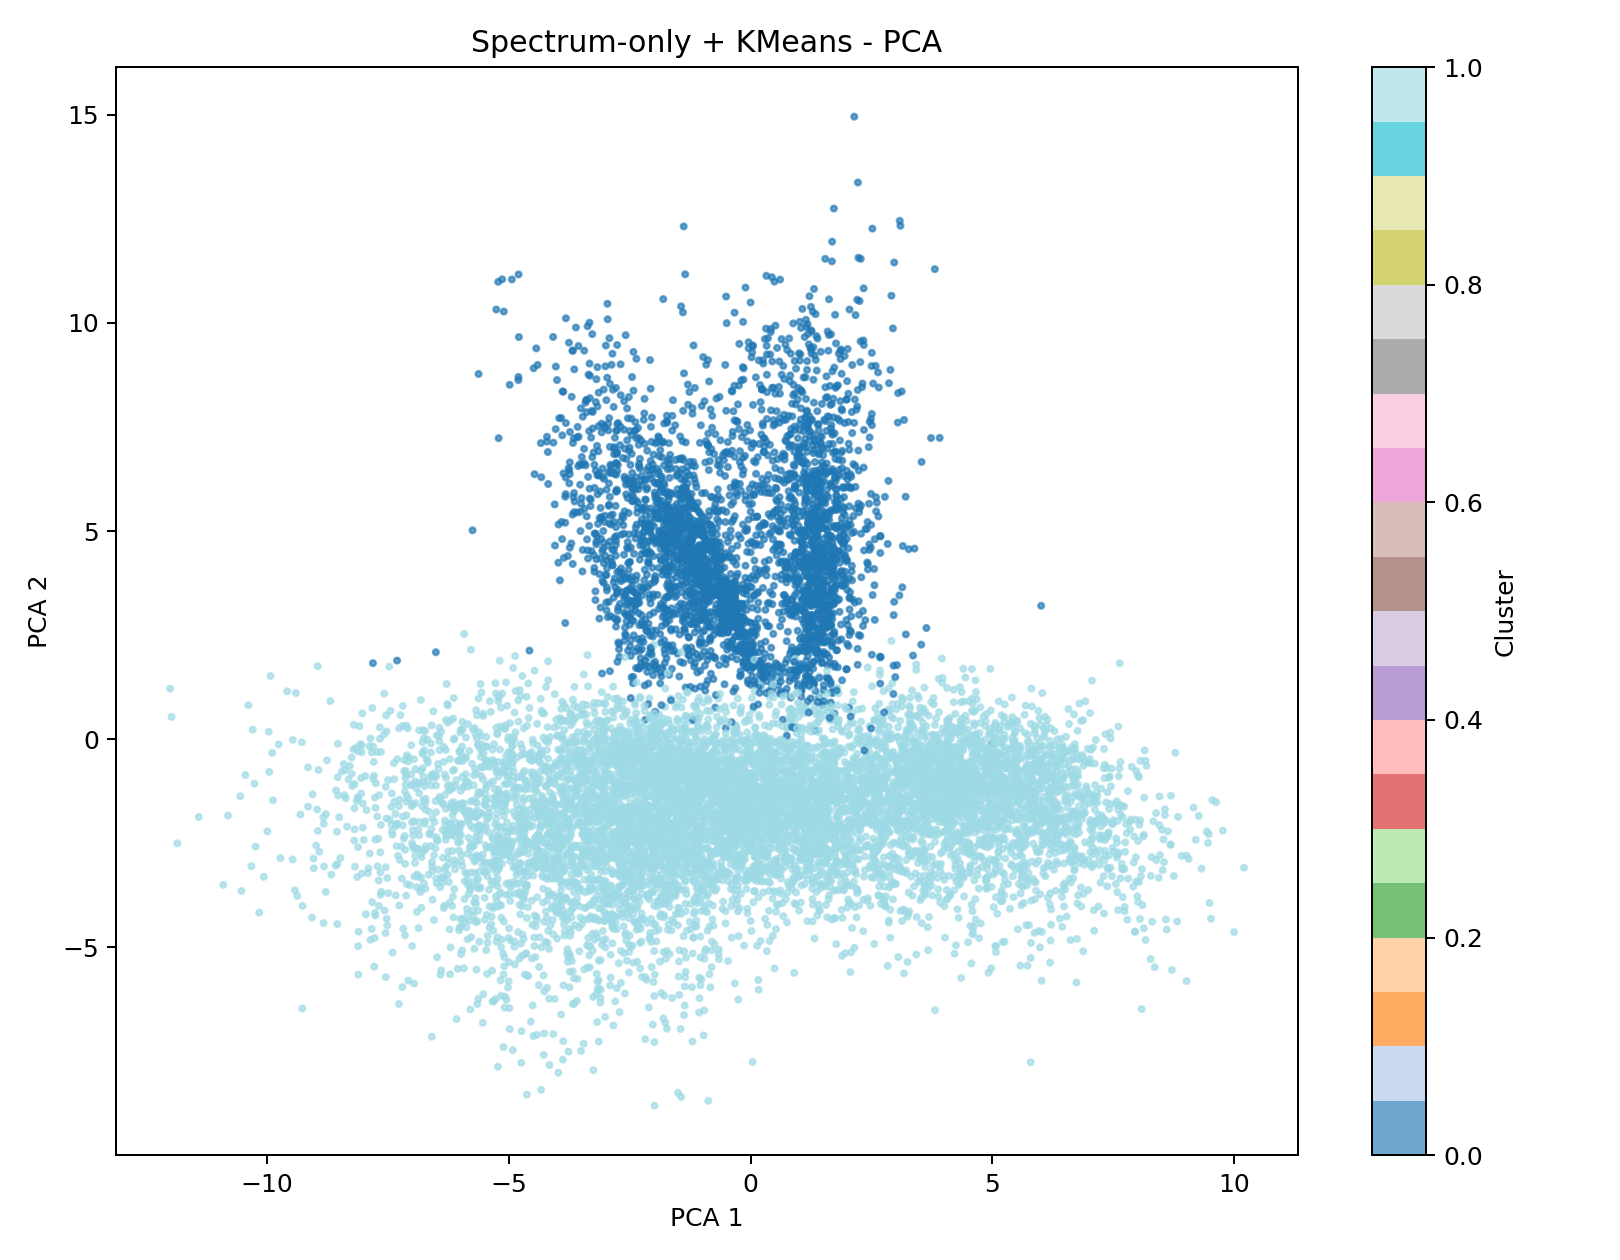

embedding_fusion_dec.png


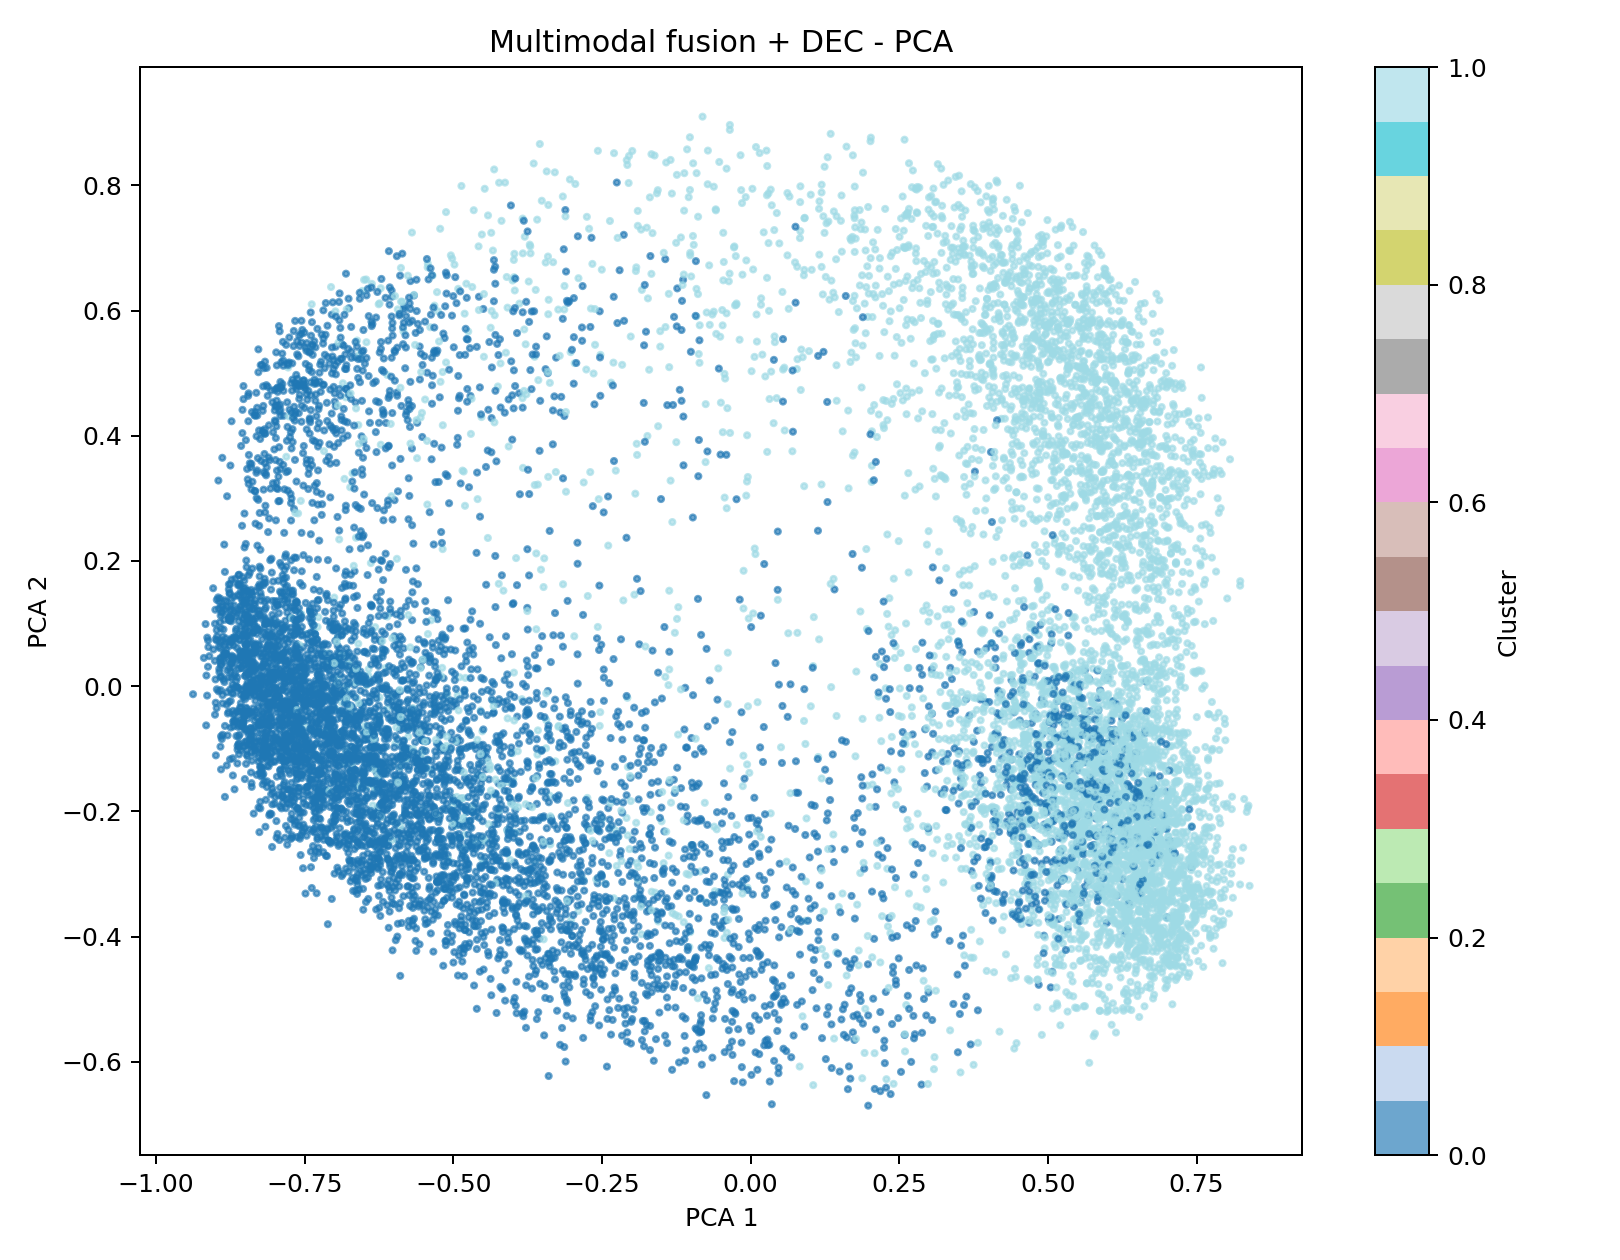

In [10]:
from pathlib import Path
from IPython.display import display, Image
import pandas as pd, json

result_dir = Path("/content/hasil_clustering")
display(pd.read_csv(result_dir / "cluster_count_metrics.csv"))
with open(result_dir / "evaluation_summary.json", encoding="utf-8") as f:
    print(json.dumps(json.load(f), indent=2, ensure_ascii=False))

for name in [
    "cluster_count_diagnostics.png",
    "embedding_fusion_kmeans.png",
    "embedding_image_only.png",
    "embedding_spectrum_only.png",
    "embedding_fusion_dec.png",
]:
    path = result_dir / name
    if path.exists():
        print(name)
        display(Image(filename=str(path)))


Download hasil program

In [11]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/hasil_clustering",
    "zip",
    root_dir="/content",
    base_dir="hasil_clustering"
)
files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>